In [5]:
import numpy as np
import pandas as pd
from google.colab import files

# Set seed for reproducibility
np.random.seed(42)

# Generate synthetic data: Screen Time (hours) vs Sleep Quality Score (0-100)
n_samples = 150
screen_time = np.random.uniform(1, 12, n_samples)  # hours per day
noise = np.random.normal(0, 5, n_samples)
sleep_quality = 95 - (5.5 * screen_time) + noise
sleep_quality = np.clip(sleep_quality, 0, 100)  # keep scores realistic

# Create DataFrame
df = pd.DataFrame({
    'Screen_Time_Hours': screen_time.round(2),
    'Sleep_Quality_Score': sleep_quality.round(2)
})

# Save to CSV
df.to_csv('screen_time_sleep_quality.csv', index=False)

# Download the file
files.download('screen_time_sleep_quality.csv')

print(df.head())
print(f"\nDataset shape: {df.shape}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

   Screen_Time_Hours  Sleep_Quality_Score
0               5.12                65.88
1              11.46                33.49
2               9.05                45.04
3               7.59                47.44
4               2.72                85.77

Dataset shape: (150, 2)


Slope (Coefficient): -5.3703
Intercept: 94.7010
Mean Squared Error: 11.8935
R² Score: 0.9692


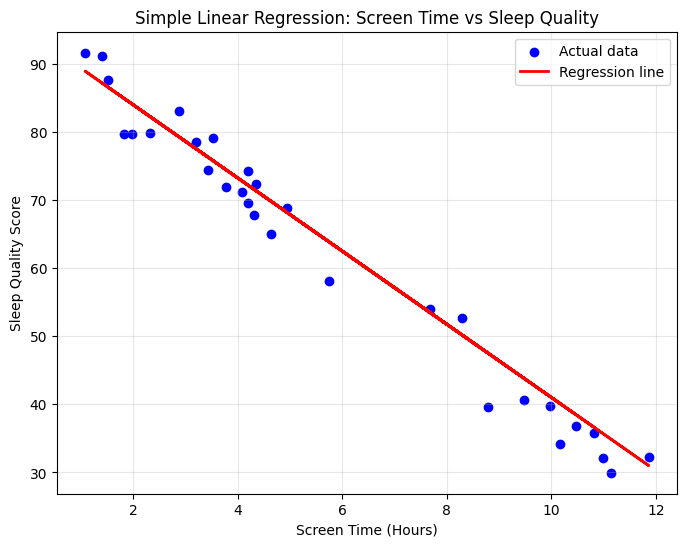


Predicted sleep quality for 6.5 hours of screen time: 59.79


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load the dataset (upload it if starting fresh, or reuse df from above)
df = pd.read_csv('screen_time_sleep_quality.csv')

# Define X (independent variable) and y (dependent variable)
X = df[['Screen_Time_Hours']]   # must be 2D
y = df['Sleep_Quality_Score']   # can be 1D

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Slope (Coefficient): {model.coef_[0]:.4f}")
print(f"Intercept: {model.intercept_:.4f}")
print(f"Mean Squared Error: {mse:.4f}")
print(f"R² Score: {r2:.4f}")

# Plot results
plt.figure(figsize=(8, 6))
plt.scatter(X_test, y_test, color='blue', label='Actual data')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Regression line')
plt.xlabel('Screen Time (Hours)')
plt.ylabel('Sleep Quality Score')
plt.title('Simple Linear Regression: Screen Time vs Sleep Quality')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Predict for a new value
new_screen_time = [[6.5]]
predicted_quality = model.predict(new_screen_time)
print(f"\nPredicted sleep quality for 6.5 hours of screen time: {predicted_quality[0]:.2f}")